# Espaço vetorial das imagens — capas e Street View

**Entrada:** a amostra de 200 anúncios de `foto_vs_review.ipynb` (4 grupos de avaliação × 2
tipos), suas capas e as 4 direções do Street View de cada um.

**Pergunta:** quando transformamos as imagens em vetores, elas se agrupam? E os grupos têm a ver
com a **nota do review**?

Cada ponto é **um Airbnb**. Dois espaços, analisados **separados** (misturados, o primeiro eixo
seria só "interior vs. rua"):

| espaço | vetor do anúncio |
|---|---|
| capa | embedding CLIP da foto de capa |
| Street View | média dos embeddings das 4 direções (0°, 90°, 180°, 270°), renormalizada |

**Método** — o mesmo de `image_clusters.ipynb`, para os resultados serem comparáveis:
CLIP ViT-B/32 (512-d, L2) → desduplicar → PCA até 90 % da variância → k-means com *k* pelo
silhouette, checando estabilidade → UMAP 2D só para **visualizar**.

**Variáveis para colorir e testar:** nota geral, accuracy, polaridade do texto dos reviews e
**preço por noite**, em duas versões:

| medida | o que é |
|---|---|
| `log_preco` | log do preço por noite (log porque a distribuição é muito assimétrica) |
| `preco_ajustado` | resíduo de `log(preço) ~ tipo + log(hóspedes)`: o quanto o anúncio é caro **para o seu tipo e capacidade**. 0 = o esperado; +0,3 ≈ 35 % acima |

Quarto privativo custa bem menos que casa/apto inteiro e os clusters não têm a mesma mistura de
tipos; com `log_preco`, um cluster pode parecer barato só por ter mais quartos.
`preco_ajustado` tira esse efeito.

**Dois testes de padrão**, porque um não depende do outro:
1. **por cluster** — a nota difere entre os clusters? (Kruskal-Wallis)
2. **por vizinhança**, sem depender de *k*: a nota (ou o preço) de um anúncio se parece com a
   dos 10 vizinhos mais próximos no espaço da imagem? (Spearman, p por permutação). Vizinho com
   imagem praticamente idêntica (cosseno > 0,97: mesmo anfitrião reaproveitando a foto, mesmo
   prédio caindo no mesmo panorama) não conta — senão a correlação sairia inflada.

Com 200 anúncios, só padrões fortes aparecem. Não achar padrão não prova que ele não existe.

## 1. Setup

In [1]:
import sys
from pathlib import Path

# umap ANTES de torch: na ordem inversa, no macOS, os dois carregam cada um o seu OpenMP e o
# kernel morre (segfault) na primeira chamada do UMAP
import umap  # noqa: I001

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib.offsetbox import AnnotationBbox, OffsetImage
from PIL import Image
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from transformers import CLIPModel, CLIPProcessor

sys.path.insert(0, "../..")  # raiz do repo (o notebook roda de notebooks/imageAnalysis/)
from src.airbnb_photos import LISTINGS  # noqa: E402
from src.amostra_reviews import FOTOS_AMOSTRA, GRUPOS  # noqa: E402
from src.streetview import HEADINGS, SAIDA as SV_DIR, e_google  # noqa: E402

ROOT = Path("../..")
PROC = ROOT / "data/processed/Airbnb"
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)

SEED = 42
K_MAX = 8
MIN_CLUSTER = 10  # clusters menores ficam fora do Kruskal (ex.: interiores que escaparam no Street View)
DUP = 0.97       # cosseno acima disso = mesma foto (ou quase)
VIZINHOS = 10
CLIP_MODEL = "openai/clip-vit-base-patch32"

amostra = pd.read_csv(ROOT / "data/interim/amostra_reviews.csv")
textos = pd.read_csv(PROC / "amostra_reviews_textos.csv", usecols=["id", "pol_media", "neg_share"])
amostra = amostra.merge(textos, on="id", how="left")
amostra["grupo"] = pd.Categorical(amostra.grupo, GRUPOS, ordered=True)

# preço por noite: bruto (log) e ajustado por tipo e capacidade
cap = pd.read_csv(LISTINGS, usecols=["id", "accommodates"], low_memory=False)
amostra = amostra.merge(cap, on="id", how="left")
amostra["preco"] = amostra.price.str.replace(r"[$,]", "", regex=True).astype(float)
amostra["log_preco"] = np.log(amostra.preco)
ok = amostra.preco.notna() & amostra.accommodates.gt(0)
X = pd.get_dummies(amostra.loc[ok, "tipo"], drop_first=True, dtype=float)
X["log_hospedes"] = np.log(amostra.loc[ok, "accommodates"])
X.insert(0, "const", 1.0)
beta, *_ = np.linalg.lstsq(X.to_numpy(), amostra.loc[ok, "log_preco"].to_numpy(), rcond=None)
amostra.loc[ok, "preco_ajustado"] = amostra.loc[ok, "log_preco"] - X.to_numpy() @ beta

print(amostra.shape, f"| com preço: {ok.sum()}")
print(f"preço mediano: R$ {amostra.preco.median():.0f} | quarto vs inteiro, mesma capacidade: "
      f"{np.exp(beta[1]) - 1:+.0%} | +1 % hóspedes -> {beta[2]:+.2f} % preço")

(200, 20) | com preço: 198
preço mediano: R$ 268 | quarto vs inteiro, mesma capacidade: -33% | +1 % hóspedes -> +0.43 % preço


## 2. Imagem → vetor

Embeddings em cache (`.npz`): rodar de novo só recalcula se alguma imagem mudou.

In [2]:
device = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
clip = CLIPModel.from_pretrained(CLIP_MODEL).to(device).eval()
proc = CLIPProcessor.from_pretrained(CLIP_MODEL)


def _norm(out):
    t = out if torch.is_tensor(out) else out.pooler_output  # transformers <5 vs >=5
    return t / t.norm(dim=-1, keepdim=True)


def embeddings(paths, cache, bs=32):
    """Cache válido só se os caminhos E as datas de modificação batem: --revisar troca a
    imagem do Street View mantendo o mesmo nome de arquivo."""
    paths = [str(p) for p in paths]
    mtimes = np.array([Path(p).stat().st_mtime_ns for p in paths])
    if Path(cache).exists():
        z = np.load(cache, allow_pickle=True)
        if list(z["paths"]) == paths and np.array_equal(z["mtimes"], mtimes):
            return z["emb"]
    out = []
    for i in range(0, len(paths), bs):
        ims = [Image.open(p).convert("RGB") for p in paths[i:i + bs]]
        with torch.no_grad():
            out.append(_norm(clip.get_image_features(**proc(images=ims, return_tensors="pt").to(device)))
                       .float().cpu().numpy())
    emb = np.vstack(out)
    np.savez(cache, emb=emb, paths=np.array(paths), mtimes=mtimes)
    return emb


print("device:", device)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

device: mps


## 3. Funções da análise

As mesmas para os dois espaços.

In [3]:
def deduplicar(E):
    """Máscara dos que ficam: em cada par com cosseno > DUP, o segundo sai."""
    S = E @ E.T
    np.fill_diagonal(S, -1)
    fora = set()
    for a, b in zip(*np.where(np.triu(S, 1) > DUP)):
        if a not in fora:
            fora.add(int(b))
    return np.array([i not in fora for i in range(len(E))])


def escolher_k(Z):
    sil = {k: silhouette_score(Z, KMeans(k, n_init=20, random_state=SEED).fit_predict(Z))
           for k in range(2, K_MAX + 1)}
    return pd.Series(sil, name="silhouette")


def estabilidade(Z, k, n=30):
    """ARI entre o k-means na amostra inteira e em reamostragens bootstrap (1 = idêntico)."""
    base = KMeans(k, n_init=20, random_state=SEED).fit(Z)
    rng = np.random.default_rng(SEED)
    ari = []
    for _ in range(n):
        idx = rng.choice(len(Z), len(Z), replace=True)
        km = KMeans(k, n_init=10, random_state=int(rng.integers(1e9))).fit(Z[idx])
        ari.append(adjusted_rand_score(base.labels_, km.predict(Z)))
    return np.array(ari)


def vizinhanca(E, y, n_perm=2000):
    """Spearman entre y e a média de y nos VIZINHOS mais próximos (cosseno); p por permutação.
    Pares com cosseno > DUP (mesma foto, mesmo panorama) não contam como vizinhos."""
    S = E @ E.T
    S[S > DUP] = -np.inf  # inclui a diagonal: imagem idêntica não é "vizinho"
    viz = np.argsort(-S, axis=1)[:, :VIZINHOS]
    y = np.asarray(y, dtype=float)
    obs = stats.spearmanr(y, y[viz].mean(1))[0]
    rng = np.random.default_rng(SEED)
    nulo = np.array([stats.spearmanr(yp, yp[viz].mean(1))[0]
                     for yp in (rng.permutation(y) for _ in range(n_perm))])
    return obs, (1 + (np.abs(nulo) >= abs(obs)).sum()) / (1 + n_perm)


def bh(p):
    p = np.asarray(p, dtype=float)
    o = np.argsort(p)
    adj = np.minimum.accumulate((p[o] * len(p) / np.arange(1, len(p) + 1))[::-1])[::-1]
    out = np.empty_like(adj)
    out[o] = adj.clip(max=1)
    return out


NOTAS = {"review_scores_rating": "nota geral", "review_scores_accuracy": "accuracy",
         "pol_media": "polaridade do texto", "log_preco": "preço por noite",
         "preco_ajustado": "preço ajustado"}


def testes(df, E):
    linhas = []
    for col, nome in NOTAS.items():
        sub = df[df[col].notna()]
        grandes = sub.cluster.value_counts().loc[lambda s: s >= MIN_CLUSTER].index
        h, p = stats.kruskal(*[g[col] for c, g in sub.groupby("cluster") if c in grandes])
        linhas.append({"teste": "entre clusters (Kruskal)", "variável": nome, "estat": h, "p": p})
        rho, pp = vizinhanca(E[df[col].notna().to_numpy()], sub[col])
        linhas.append({"teste": f"vizinhança ({VIZINHOS}-NN, Spearman)", "variável": nome,
                       "estat": rho, "p": pp})
    for col in ["grupo", "tipo"]:
        chi, p, *_ = stats.chi2_contingency(pd.crosstab(df.cluster, df[col]))
        linhas.append({"teste": "cluster × " + col + " (qui²)", "variável": col, "estat": chi, "p": p})
    R = pd.DataFrame(linhas)
    R["p_bh"] = bh(R.p)
    R["sig"] = R.p_bh < 0.05
    return R

In [4]:
CORES_CLUSTER = plt.cm.tab10.colors
MARCADORES = "osD^vP*Xph"


def plot_espaco(df, titulo, cor="review_scores_rating", salvar=None):
    """Esquerda: clusters. Direita: cada Airbnb colorido por `cor` (nota por padrão), com o
    formato do marcador indicando o cluster — os dois ao mesmo tempo."""
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 6.5))
    for c, g in df.groupby("cluster"):
        a1.scatter(g.u1, g.u2, s=45, color=CORES_CLUSTER[c % 10], marker=MARCADORES[c % 10],
                   edgecolor="white", linewidth=0.5, label=f"cluster {c} (n={len(g)})")
        a1.annotate(str(c), (g.u1.median(), g.u2.median()), fontsize=14, weight="bold",
                    ha="center", va="center", color="black")
    a1.legend(fontsize=8, loc="best")
    a1.set_title("clusters (k-means)")

    num = pd.api.types.is_numeric_dtype(df[cor])
    if num:
        d = df.dropna(subset=[cor])
        if cor == "log_preco":
            (vmin, vmax), cmap = d[cor].quantile([0.03, 0.97]), "viridis"
        elif cor == "preco_ajustado":  # divergente: vermelho = mais caro que o esperado
            m = d[cor].abs().quantile(0.95)
            vmin, vmax, cmap = -m, m, "RdBu_r"
        else:
            (vmin, vmax), cmap = d[cor].quantile([0.05, 1.0]), "RdYlBu"
        for c, g in d.groupby("cluster"):
            sc = a2.scatter(g.u1, g.u2, c=g[cor], cmap=cmap, vmin=vmin, vmax=vmax, s=55,
                            marker=MARCADORES[c % 10], edgecolor="black", linewidth=0.3)
        cb = fig.colorbar(sc, ax=a2, label=NOTAS.get(cor, cor))
        if cor == "log_preco":
            ticks = [t for t in (100, 150, 200, 300, 500, 800) if vmin <= np.log(t) <= vmax]
            cb.set_ticks(np.log(ticks), labels=[f"R$ {t}" for t in ticks])
    else:
        pal = dict(zip(df[cor].cat.categories if hasattr(df[cor], "cat") else sorted(df[cor].unique()),
                       ["#b2182b", "#ef8a62", "#999999", "#2166ac", "#4daf4a", "#984ea3"]))
        for c, g in df.groupby("cluster"):
            a2.scatter(g.u1, g.u2, c=g[cor].map(pal).tolist(), s=55, marker=MARCADORES[c % 10],
                       edgecolor="black", linewidth=0.3)
        for k, v in pal.items():
            a2.scatter([], [], color=v, label=k)
        a2.legend(fontsize=8)
    a2.set_title(f"cor = {NOTAS.get(cor, cor)} · marcador = cluster")
    for a in (a1, a2):
        a.set_xticks([]); a.set_yticks([])
    fig.suptitle(titulo, fontsize=13)
    fig.tight_layout()
    if salvar:
        fig.savefig(OUT / salvar, dpi=110, bbox_inches="tight")
    plt.show()


def miniaturas(df, coluna_foto, titulo, salvar=None, zoom=0.11):
    fig, ax = plt.subplots(figsize=(15, 12))
    ax.scatter(df.u1, df.u2, s=0)
    for r in df.itertuples():
        im = Image.open(getattr(r, coluna_foto)).convert("RGB")
        im.thumbnail((256, 256))
        ab = AnnotationBbox(OffsetImage(im, zoom=zoom * 2.5), (r.u1, r.u2), frameon=True,
                            bboxprops={"edgecolor": CORES_CLUSTER[r.cluster % 10], "lw": 2})
        ax.add_artist(ab)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(titulo + " — moldura = cor do cluster")
    if salvar:
        fig.savefig(OUT / salvar, dpi=90, bbox_inches="tight")
    plt.show()


def exemplos(df, Z, km, coluna_foto, titulo, n=8, salvar=None):
    """As n fotos mais próximas do centro de cada cluster — o que o cluster 'é'."""
    d = np.linalg.norm(Z - km.cluster_centers_[df.cluster.to_numpy()], axis=1)
    df = df.assign(_d=d)
    ks = sorted(df.cluster.unique())
    fig, axes = plt.subplots(len(ks), n, figsize=(2.1 * n, 2.3 * len(ks)))
    axes = np.atleast_2d(axes)
    for i, c in enumerate(ks):
        g = df[df.cluster == c].nsmallest(n, "_d")
        for j in range(n):
            ax = axes[i, j]
            ax.axis("off")
            if j < len(g):
                r = g.iloc[j]
                ax.imshow(Image.open(r[coluna_foto]))
                ax.set_title(f"{r.review_scores_rating:.2f}", fontsize=8)
        axes[i, 0].text(-0.15, 0.5, f"cluster {c}\nn={int((df.cluster == c).sum())}\n"
                        f"nota med {df.loc[df.cluster == c, 'review_scores_rating'].median():.2f}",
                        transform=axes[i, 0].transAxes, ha="right", va="center", fontsize=9)
    fig.suptitle(titulo + " — fotos mais centrais de cada cluster (título = nota)", fontsize=11)
    fig.tight_layout()
    if salvar:
        fig.savefig(OUT / salvar, dpi=90, bbox_inches="tight")
    plt.show()


def resumo(df):
    return (df.groupby("cluster")
              .agg(n=("id", "size"), nota_med=("review_scores_rating", "median"),
                   accuracy_med=("review_scores_accuracy", "median"), pol_med=("pol_media", "median"),
                   preco_med=("preco", "median"), preco_ajust_med=("preco_ajustado", "median"),
                   pct_quarto=("tipo", lambda s: (s == "quarto").mean()))
              .round(3)
              .join(pd.crosstab(df.cluster, df.grupo.astype(str))
                      .reindex(columns=GRUPOS, fill_value=0)))


def pipeline(E, df):
    """Desduplica, PCA, escolhe k, ajusta k-means nos únicos e rotula todos; UMAP p/ plot."""
    keep = deduplicar(E)
    pca = PCA(0.90, random_state=SEED).fit(E[keep])
    Z = pca.transform(E)
    print(f"duplicados fora do ajuste: {(~keep).sum()} | PCA: {pca.n_components_} componentes")
    sil = escolher_k(Z[keep])
    return keep, pca, Z, sil

## 4. Capas

### 4.1 Vetores e escolha de *k*

capas: (200, 512)
duplicados fora do ajuste: 3 | PCA: 66 componentes


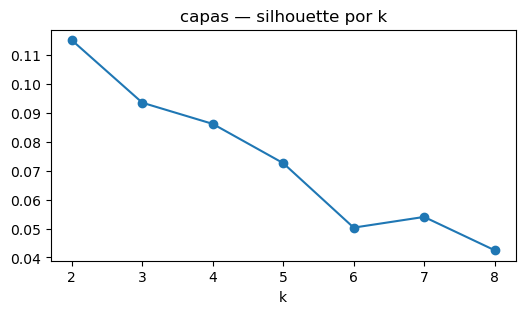

2    0.115
3    0.094
4    0.086
5    0.073
6    0.050
7    0.054
8    0.042
Name: silhouette, dtype: float32

In [5]:
capas = amostra.assign(foto=amostra.id.map(lambda i: str(FOTOS_AMOSTRA / f"{i}.jpg")))
capas = capas[capas.foto.map(lambda p: Path(p).exists())].reset_index(drop=True)
E_capa = embeddings(capas.foto, PROC / "amostra_clip_capas.npz")
print("capas:", E_capa.shape)

keep_c, pca_c, Z_c, sil_c = pipeline(E_capa, capas)
ax = sil_c.plot(marker="o", figsize=(6, 3), title="capas — silhouette por k")
ax.set_xlabel("k"); plt.show()
sil_c.round(3)

O silhouette de fotos de interiores costuma ser baixo (≈0,05–0,15): as fotos formam um contínuo,
não ilhas separadas. *k* é o do maior silhouette; a estabilidade diz se ele se sustenta.

In [6]:
K_CAPA = int(sil_c.idxmax())
ari = estabilidade(Z_c[keep_c], K_CAPA)
print(f"k = {K_CAPA} | estabilidade ARI: mediana {np.median(ari):.2f} (p10 {np.quantile(ari, .1):.2f})")

km_c = KMeans(K_CAPA, n_init=20, random_state=SEED).fit(Z_c[keep_c])
capas["cluster"] = km_c.predict(Z_c)
capas[["u1", "u2"]] = umap.UMAP(n_neighbors=15, min_dist=0.15, random_state=SEED).fit_transform(Z_c)
resumo(capas)

k = 2 | estabilidade ARI: mediana 0.70 (p10 -0.00)


/opt/anaconda3/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


,n,nota_med,accuracy_med,pol_med,preco_med,preco_ajust_med,pct_quarto,accuracy_baixa,nota_baixa,nota_media,nota_alta
cluster,,,,,,,,,,,
0,122,4.615,4.695,0.292,241.00,-0.02,0.533,29,37,30,26
1,78,4.725,4.760,0.319,304.01,0.01,0.397,21,13,20,24


### 4.2 O espaço — cor = nota do review

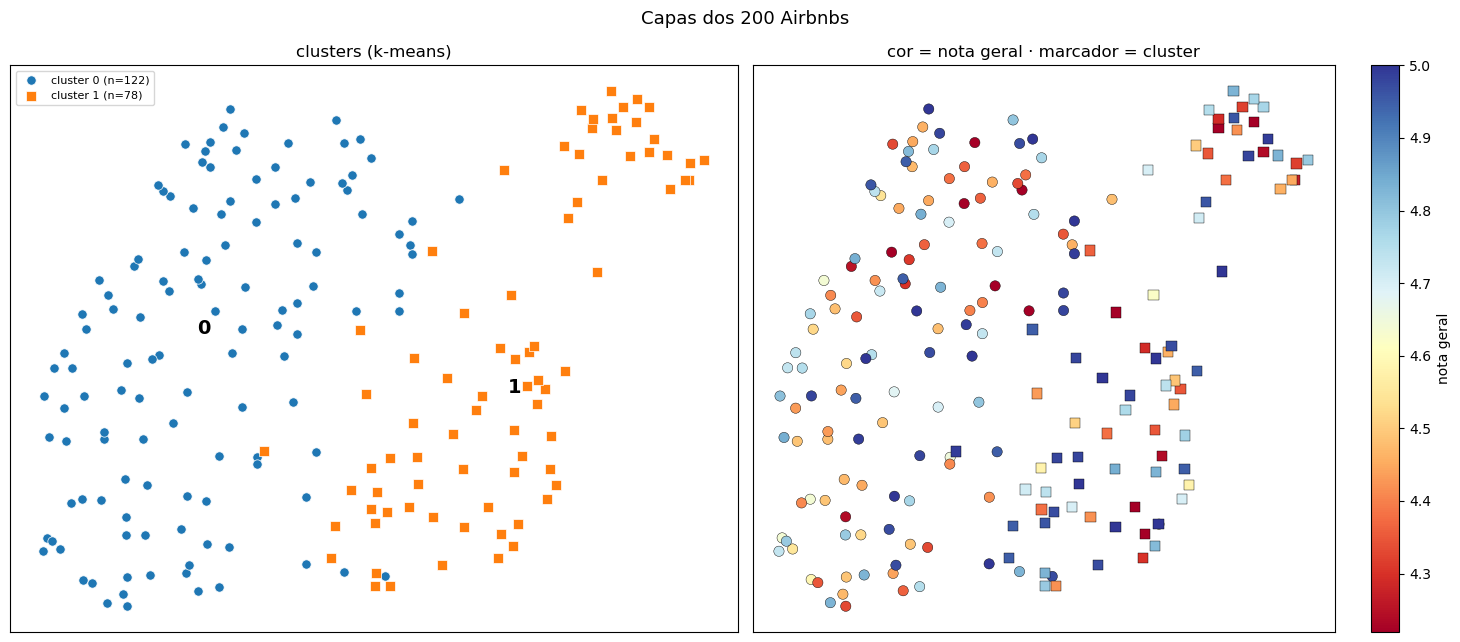

In [7]:
plot_espaco(capas, "Capas dos 200 Airbnbs", cor="review_scores_rating", salvar="clusters_amostra_capas.png")

Outras colorações: `cor="review_scores_accuracy"`, `cor="pol_media"` (polaridade do texto dos
reviews) ou `cor="grupo"`.

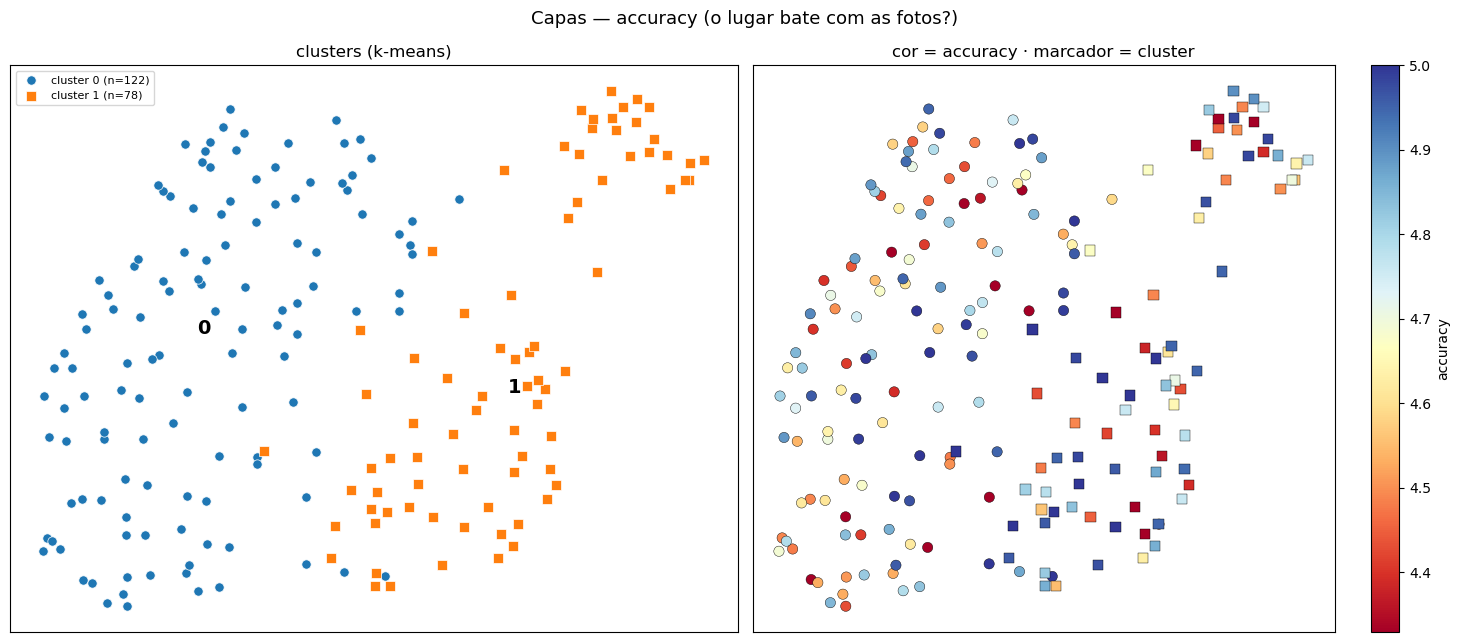

In [8]:
plot_espaco(capas, "Capas — accuracy (o lugar bate com as fotos?)", cor="review_scores_accuracy")

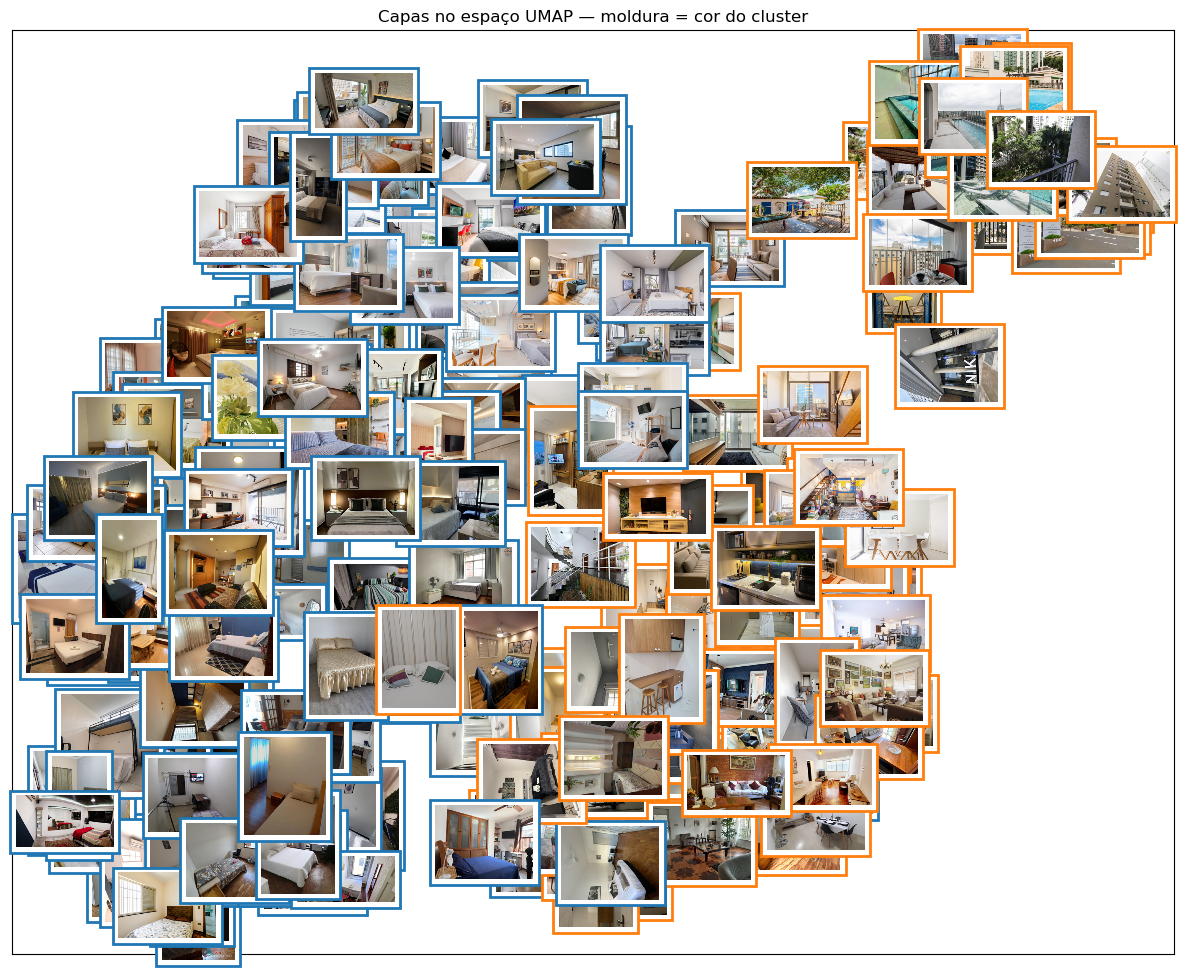

In [9]:
miniaturas(capas, "foto", "Capas no espaço UMAP", salvar="clusters_amostra_capas_miniaturas.png")

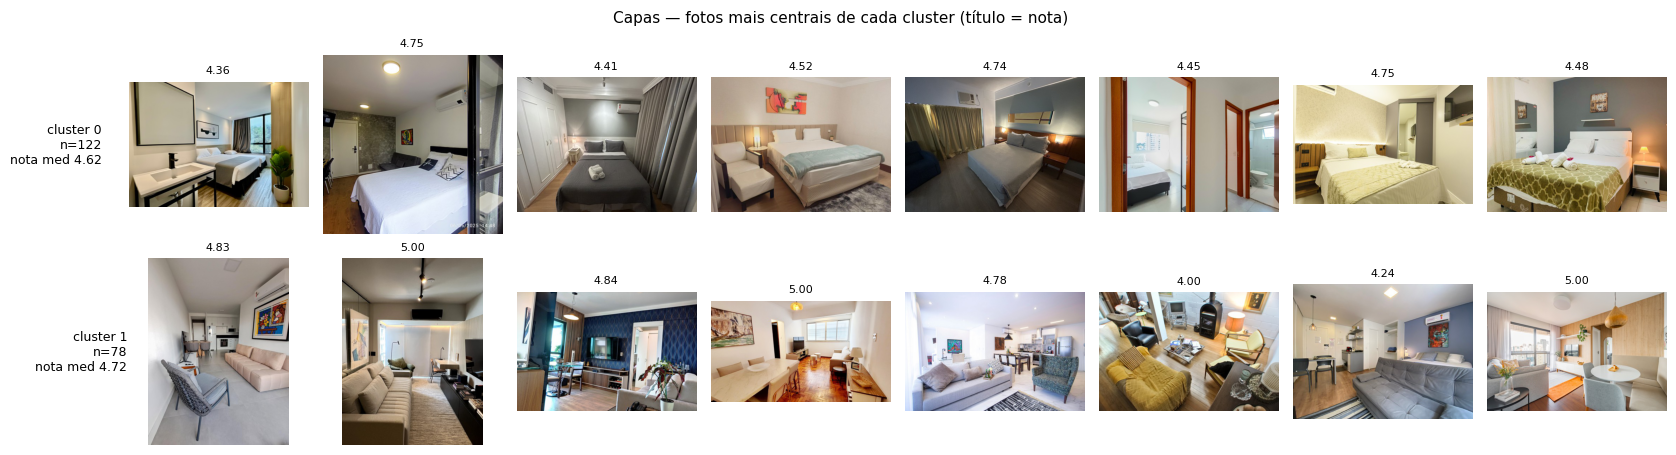

In [10]:
exemplos(capas, Z_c, km_c, "foto", "Capas", salvar="clusters_amostra_capas_exemplos.png")

### 4.3 Cor = preço por noite

Esquerda do painel: clusters. Direita: preço. Depois, o preço ajustado — vermelho = mais caro
do que o tipo e a capacidade do anúncio explicam, azul = mais barato.

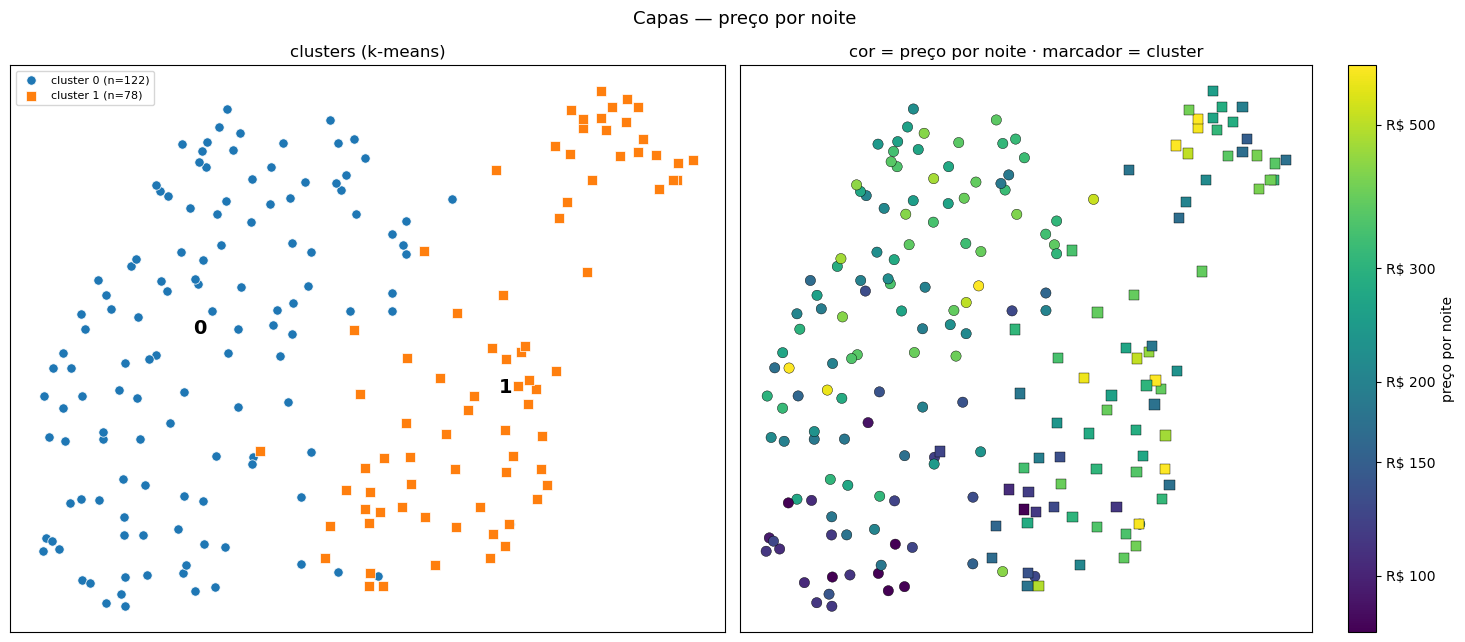

In [11]:
plot_espaco(capas, "Capas — preço por noite", cor="log_preco", salvar="clusters_amostra_capas_preco.png")

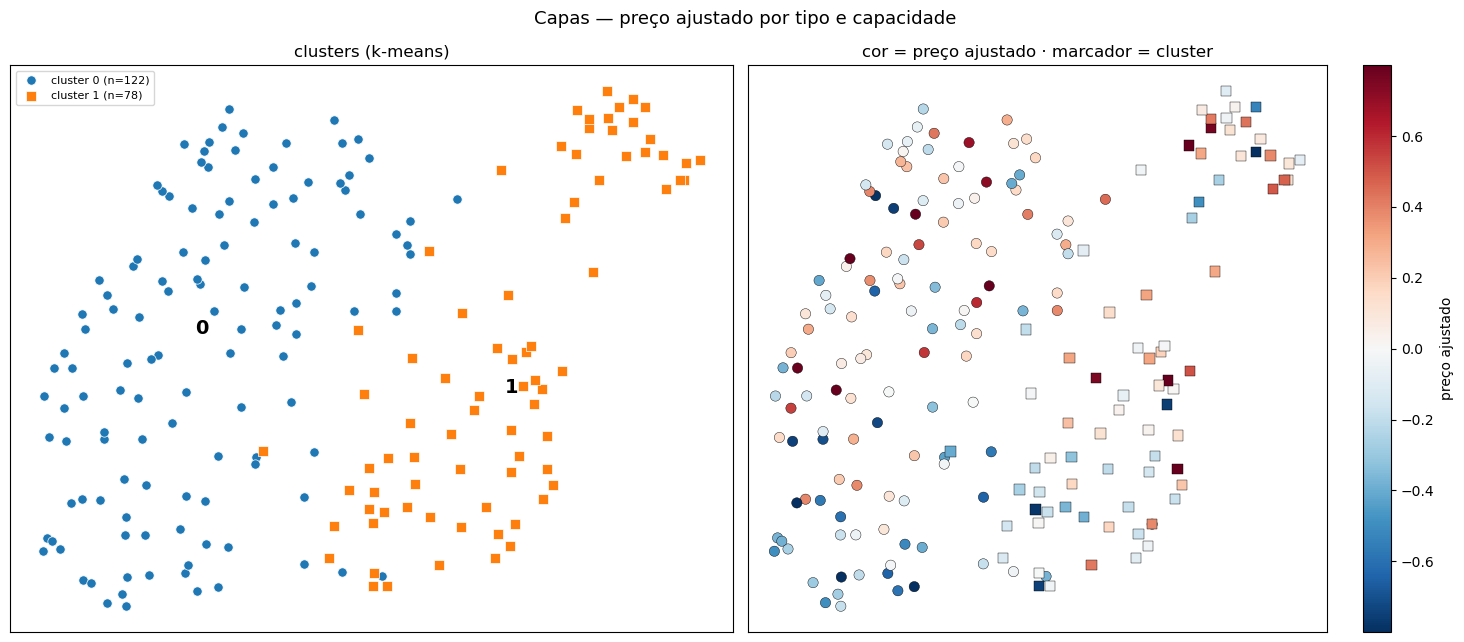

In [12]:
plot_espaco(capas, "Capas — preço ajustado por tipo e capacidade", cor="preco_ajustado",
            salvar="clusters_amostra_capas_preco_ajustado.png")

### 4.4 Existe padrão com a nota ou com o preço?

In [13]:
R_capa = testes(capas, E_capa)
R_capa.round(4)

,teste,variável,estat,p,p_bh,sig
0,entre clusters (Kruskal),nota geral,0.3972,0.5285,0.6342,False
1,"vizinhança (10-NN, Spearman)",nota geral,0.0432,0.6157,0.6717,False
2,entre clusters (Kruskal),accuracy,0.7112,0.3990,0.5986,False
3,"vizinhança (10-NN, Spearman)",accuracy,-0.0571,0.5062,0.6342,False
4,entre clusters (Kruskal),polaridade do texto,2.1264,0.1448,0.2896,False
5,"vizinhança (10-NN, Spearman)",polaridade do texto,0.0302,0.7186,0.7186,False
6,entre clusters (Kruskal),preço por noite,6.0023,0.0143,0.0571,False
7,"vizinhança (10-NN, Spearman)",preço por noite,0.5686,0.0005,0.0030,True
8,entre clusters (Kruskal),preço ajustado,1.4389,0.2303,0.3948,False
9,"vizinhança (10-NN, Spearman)",preço ajustado,0.3812,0.0005,0.0030,True


## 5. Street View

Só panoramas do carro do Google (`copyright` "© Google" no `manifest.csv`): fotos 360° de
terceiros mostram interior de loja ou hall de prédio, não o entorno. Se o manifest ainda não
tem a coluna `copyright`, rode antes
`python scripts/fetch_streetview.py --ids-arquivo data/interim/amostra_reviews_ids.txt --revisar`.

Lembrete: a coordenada do Inside Airbnb é deslocada em até ~150 m — é o **entorno** do anúncio,
não a fachada.

In [14]:
man = pd.read_csv(SV_DIR / "manifest.csv")
# "existente" = já tinha imagens e o --revisar confirmou o panorama; "ok" = baixado/trocado
man = man[man.id.isin(amostra.id) & man.status.isin(["ok", "existente"])]
if "copyright" in man:
    n0 = len(man)
    man = man[man.apply(e_google, axis=1)]
    print(f"panoramas do Google: {len(man)} de {n0}")
else:
    print("AVISO: manifest sem copyright -- pode haver panoramas de terceiros (rode --revisar)")

arquivos = {i: [SV_DIR / f"{i}_{h}.jpg" for h in HEADINGS] for i in man.id}
arquivos = {i: fs for i, fs in arquivos.items() if all(f.exists() for f in fs)}
sv = amostra[amostra.id.isin(arquivos)].reset_index(drop=True)
sv["foto"] = sv.id.map(lambda i: str(arquivos[i][0]))  # heading 0, para as miniaturas

todas = [f for i in sv.id for f in arquivos[i]]
E_img = embeddings(todas, PROC / "amostra_clip_streetview.npz")
E_sv = E_img.reshape(len(sv), len(HEADINGS), -1).mean(1)
E_sv /= np.linalg.norm(E_sv, axis=1, keepdims=True)
print("anúncios:", E_sv.shape, "| imagens:", E_img.shape)
print(sv.groupby("grupo", observed=True).size().to_string())

panoramas do Google: 199 de 199
anúncios: (199, 512) | imagens: (796, 512)
grupo
accuracy_baixa    49
nota_baixa        50
nota_media        50
nota_alta         50


Anúncios no mesmo prédio podem cair no **mesmo panorama** — vetores idênticos. Eles ficam fora
do ajuste do k-means (senão formariam um cluster artificial) e depois recebem o cluster do vizinho.

duplicados fora do ajuste: 10 | PCA: 45 componentes


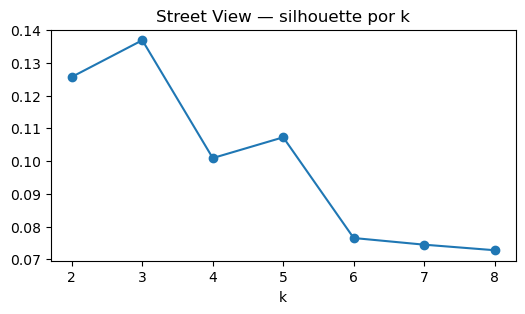

k = 3 | estabilidade ARI: mediana 0.92 (p10 0.84)


/opt/anaconda3/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


,n,nota_med,accuracy_med,pol_med,preco_med,preco_ajust_med,pct_quarto,accuracy_baixa,nota_baixa,nota_media,nota_alta
cluster,,,,,,,,,,,
0,5,4.480,4.58,0.223,192.860,-0.013,0.600,2,1,1,1
1,110,4.635,4.71,0.302,313.835,0.116,0.364,24,32,28,26
2,84,4.710,4.78,0.305,194.000,-0.179,0.631,23,17,21,23


In [15]:
keep_s, pca_s, Z_s, sil_s = pipeline(E_sv, sv)
ax = sil_s.plot(marker="o", figsize=(6, 3), title="Street View — silhouette por k")
ax.set_xlabel("k"); plt.show()

K_SV = int(sil_s.idxmax())
ari = estabilidade(Z_s[keep_s], K_SV)
print(f"k = {K_SV} | estabilidade ARI: mediana {np.median(ari):.2f} (p10 {np.quantile(ari, .1):.2f})")

km_s = KMeans(K_SV, n_init=20, random_state=SEED).fit(Z_s[keep_s])
sv["cluster"] = km_s.predict(Z_s)
sv[["u1", "u2"]] = umap.UMAP(n_neighbors=15, min_dist=0.15, random_state=SEED).fit_transform(Z_s)
resumo(sv)

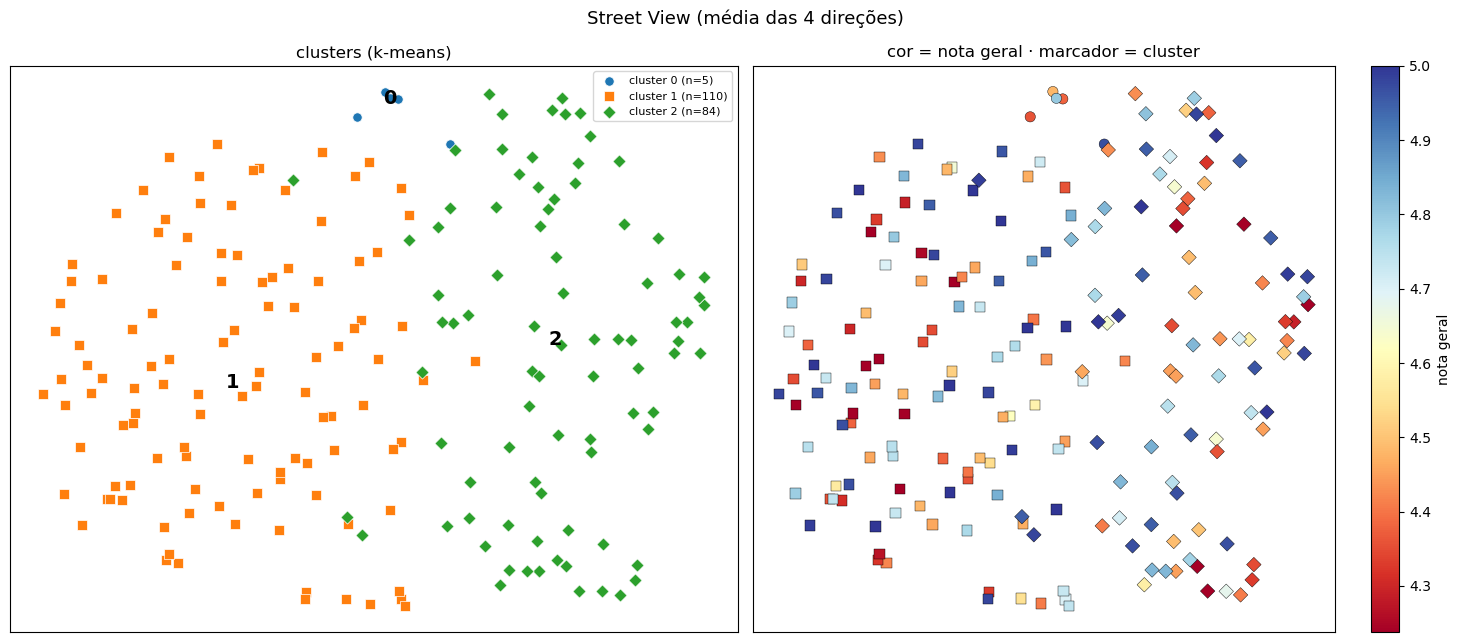

In [16]:
plot_espaco(sv, "Street View (média das 4 direções)", cor="review_scores_rating",
            salvar="clusters_amostra_streetview.png")

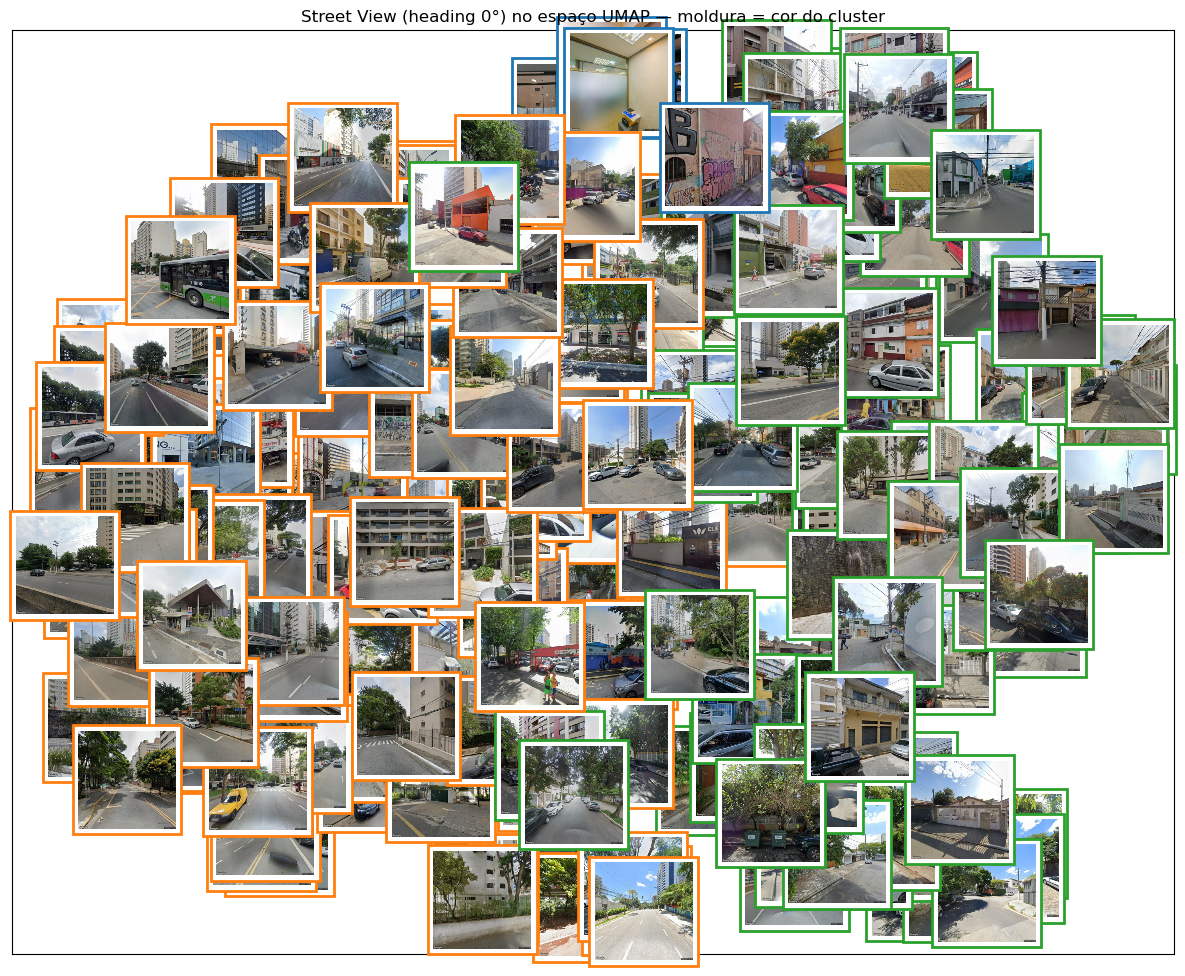

In [17]:
miniaturas(sv, "foto", "Street View (heading 0°) no espaço UMAP",
           salvar="clusters_amostra_streetview_miniaturas.png")

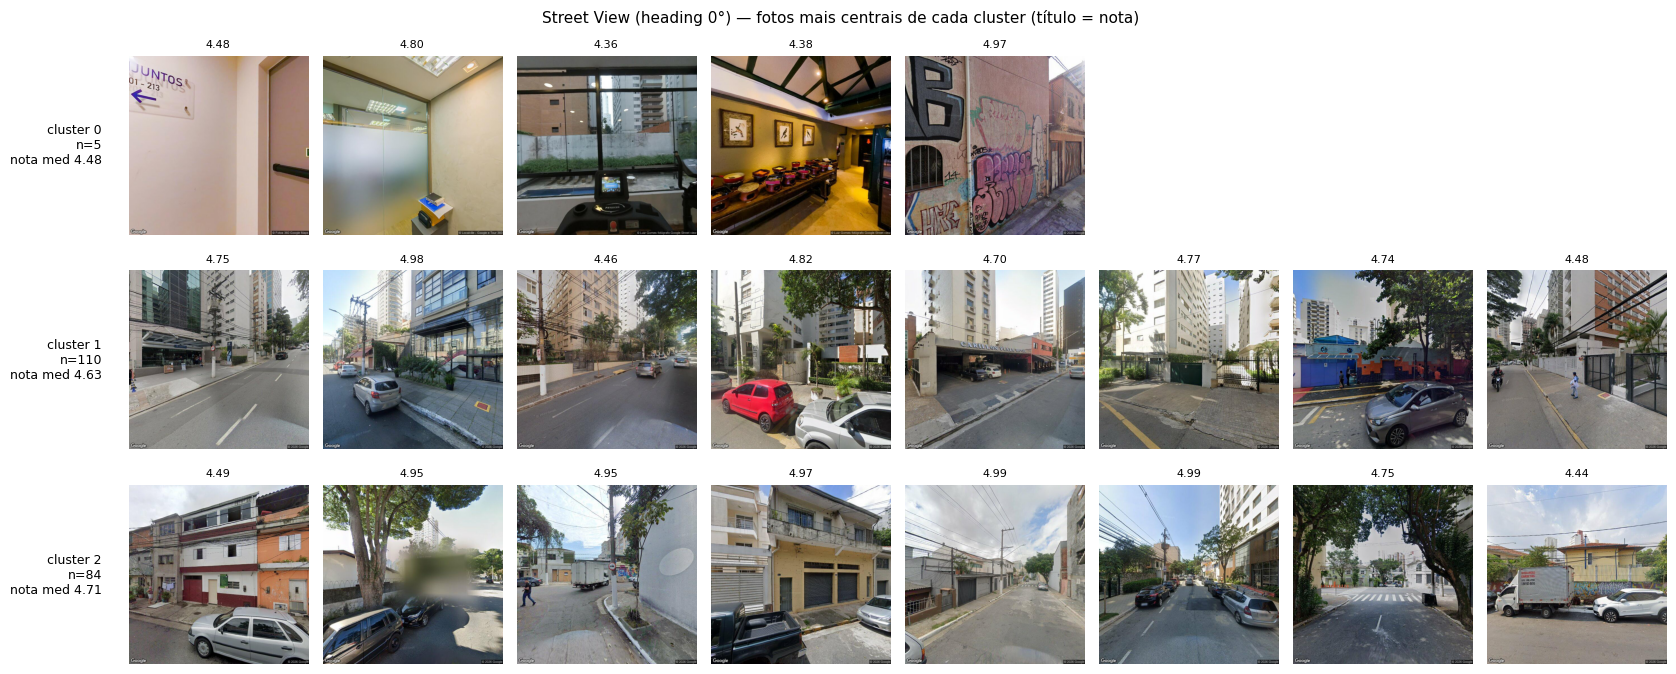

In [18]:
exemplos(sv, Z_s, km_s, "foto", "Street View (heading 0°)", salvar="clusters_amostra_streetview_exemplos.png")

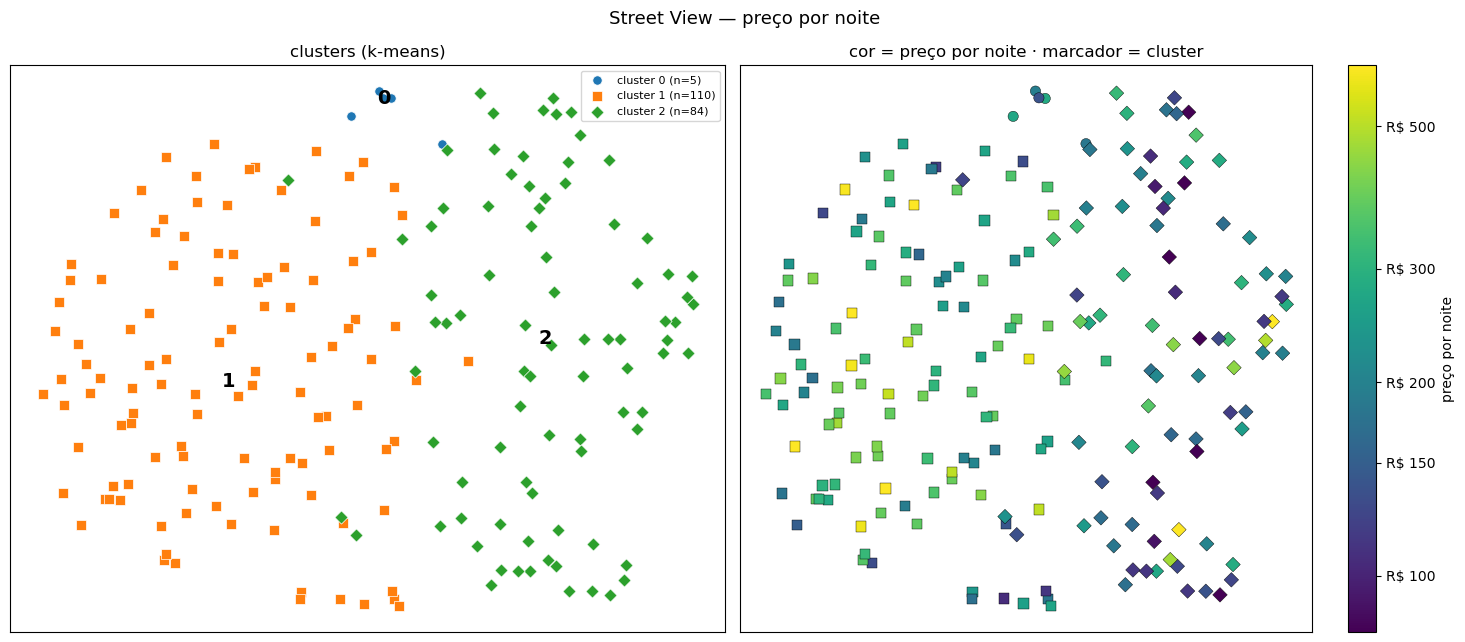

In [19]:
plot_espaco(sv, "Street View — preço por noite", cor="log_preco",
            salvar="clusters_amostra_streetview_preco.png")

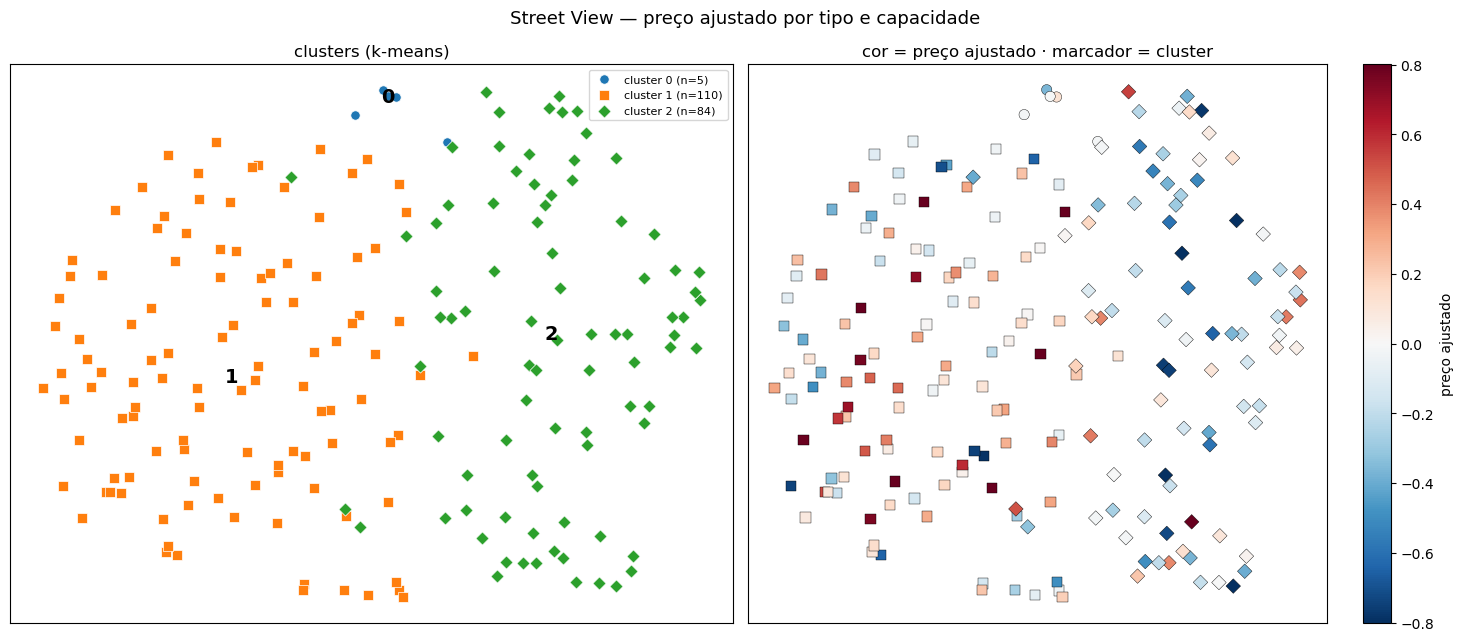

In [20]:
plot_espaco(sv, "Street View — preço ajustado por tipo e capacidade", cor="preco_ajustado",
            salvar="clusters_amostra_streetview_preco_ajustado.png")

In [21]:
R_sv = testes(sv, E_sv)
R_sv.round(4)

,teste,variável,estat,p,p_bh,sig
0,entre clusters (Kruskal),nota geral,0.6955,0.4043,0.6064,False
1,"vizinhança (10-NN, Spearman)",nota geral,0.1039,0.2269,0.4001,False
2,entre clusters (Kruskal),accuracy,0.0002,0.9887,0.9887,False
3,"vizinhança (10-NN, Spearman)",accuracy,0.0999,0.2334,0.4001,False
4,entre clusters (Kruskal),polaridade do texto,0.3710,0.5425,0.6510,False
5,"vizinhança (10-NN, Spearman)",polaridade do texto,0.0600,0.4888,0.6510,False
6,entre clusters (Kruskal),preço por noite,34.0072,0.0000,0.0000,True
7,"vizinhança (10-NN, Spearman)",preço por noite,0.4743,0.0005,0.0015,True
8,entre clusters (Kruskal),preço ajustado,23.9026,0.0000,0.0000,True
9,"vizinhança (10-NN, Spearman)",preço ajustado,0.3415,0.0005,0.0015,True


**Como ler:** se `log_preco` dá padrão e `preco_ajustado` não, o padrão vem do tipo de anúncio
(quarto vs. inteiro), não da imagem. Se os dois dão, a imagem carrega informação de preço além
do tipo e da capacidade.

## 6. Gravar

In [22]:
saida = (amostra[["id", "grupo", "tipo", "review_scores_rating", "review_scores_accuracy", "pol_media",
                  "preco", "preco_ajustado"]]
         .merge(capas[["id", "cluster", "u1", "u2"]].rename(columns=lambda c: c if c == "id" else f"capa_{c}"),
                on="id", how="left")
         .merge(sv[["id", "cluster", "u1", "u2"]].rename(columns=lambda c: c if c == "id" else f"sv_{c}"),
                on="id", how="left"))
saida.to_csv(PROC / "amostra_clusters.csv", index=False)
print(saida.shape)
print(pd.crosstab(saida.capa_cluster, saida.sv_cluster, dropna=False))

(200, 14)
sv_cluster    0.0  1.0  2.0  NaN
capa_cluster                    
0               4   69   49    0
1               1   41   35    1


## 7. Leitura

*Preencher depois de olhar as figuras.* Ver nos exemplos o que cada cluster **é** (quarto,
sala, fachada, piscina; rua residencial, avenida, área verde...) antes de nomeá-lo — o número do
cluster não significa nada.